In [1]:
# ============================================================
# ROLE E — EVALUATION & VISUALIZATION NOTEBOOK
# Project: Concept Drifters — COMPX523 Assignment 3
# Purpose:
#   1. Load Role C and Role D output files
#   2. Create polished model evaluation graphs
#   3. Create peak-boundary and schedule-alignment visualizations
#   4. Save figures and summary tables for report/presentation
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import textwrap

# -----------------------------
# Find project root automatically
# -----------------------------
CURRENT_DIR = Path.cwd()

def find_project_root(start_path):
    """
    Walk upward from the current notebook location until we find
    the project root containing outputs/ and figures/.
    """
    start_path = Path(start_path).resolve()
    
    for path in [start_path] + list(start_path.parents):
        if (path / "outputs").exists() and (path / "figures").exists():
            return path
    
    raise FileNotFoundError(
        "Could not find project root. Make sure the notebook is inside the project folder."
    )

PROJECT_DIR = find_project_root(CURRENT_DIR)

OUTPUT_DIR = PROJECT_DIR / "outputs"
FIG_DIR = PROJECT_DIR / "figures"
ROLE_E_DIR = PROJECT_DIR / "docs" / "role_E_evaluation_viz"

# New polished output folder
POLISHED_FIG_DIR = FIG_DIR / "role_E_polished"
POLISHED_TABLE_DIR = OUTPUT_DIR / "role_E_polished"

POLISHED_FIG_DIR.mkdir(parents=True, exist_ok=True)
POLISHED_TABLE_DIR.mkdir(parents=True, exist_ok=True)
ROLE_E_DIR.mkdir(parents=True, exist_ok=True)

print("Current notebook folder:", CURRENT_DIR)
print("Project folder:", PROJECT_DIR)
print("Outputs folder:", OUTPUT_DIR)
print("Figures folder:", FIG_DIR)
print("Polished figures folder:", POLISHED_FIG_DIR)

Current notebook folder: D:\MLDS\concept_drifter\docs\role_E_evaluation_viz
Project folder: D:\MLDS\concept_drifter
Outputs folder: D:\MLDS\concept_drifter\outputs
Figures folder: D:\MLDS\concept_drifter\figures
Polished figures folder: D:\MLDS\concept_drifter\figures\role_E_polished


In [2]:
# ============================================================
# GLOBAL PLOT STYLE
# Makes all figures consistent and report-ready
# ============================================================

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except:
    plt.style.use("default")

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "axes.edgecolor": "#333333",
    "axes.linewidth": 0.8,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.frameon": True,
    "legend.framealpha": 0.95,
    "grid.alpha": 0.25,
})

# Consistent colors
COLORS = {
    "blue": "#2F6BFF",
    "green": "#2CA02C",
    "orange": "#FF9F1C",
    "red": "#D62728",
    "purple": "#7B2CBF",
    "gray": "#6C757D",
    "dark": "#1F2937",
    "light_blue": "#A7C7E7",
    "light_red": "#F4A6A6"
}

MODEL_COLORS = [
    "#2F6BFF", "#FF9F1C", "#2CA02C", "#D62728",
    "#7B2CBF", "#17BECF", "#8C564B", "#E377C2"
]

print("Plot style loaded successfully.")

Plot style loaded successfully.


In [3]:
# ============================================================
# HELPER FUNCTIONS
# These functions keep the notebook clean and reusable.
# ============================================================

def clean_columns(df):
    """
    Standardize column names:
    - lowercase
    - remove spaces
    - replace hyphens with underscores
    """
    df = df.copy()
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace("-", "_")
    )
    return df


def save_figure(filename):
    """
    Save the current matplotlib figure into the polished figure folder.
    """
    path = POLISHED_FIG_DIR / filename
    plt.savefig(path, bbox_inches="tight", dpi=300)
    print("Saved figure:", path)
    return path


def minutes_to_hhmm(x):
    """
    Convert minutes after midnight into HH:MM clock time.
    Example: 390 -> 06:30
    """
    if pd.isna(x):
        return np.nan
    
    x = int(round(float(x)))
    h = x // 60
    m = x % 60
    return f"{h:02d}:{m:02d}"


def hhmm_axis_formatter(x, pos):
    """
    Formatter for y-axis when values are minutes after midnight.
    """
    if pd.isna(x):
        return ""
    x = int(round(x))
    h = x // 60
    m = x % 60
    return f"{h:02d}:{m:02d}"


def wrap_labels(labels, width=18):
    """
    Wrap long labels for better chart readability.
    """
    return ["\n".join(textwrap.wrap(str(label), width=width)) for label in labels]


def add_value_labels_horizontal(ax, values, fmt="{:.2f}", offset=0.02):
    """
    Add value labels to horizontal bar charts.
    """
    max_val = max(abs(v) for v in values) if len(values) else 1
    
    for i, v in enumerate(values):
        label = fmt.format(v)
        if v >= 0:
            ax.text(v + max_val * offset, i, label, va="center", ha="left", fontsize=9)
        else:
            ax.text(v - max_val * offset, i, label, va="center", ha="right", fontsize=9)


def add_value_labels_vertical(ax, bars, fmt="{:.2f}"):
    """
    Add value labels above vertical bars.
    """
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            fmt.format(height),
            ha="center",
            va="bottom",
            fontsize=9
        )

print("Helper functions ready.")

Helper functions ready.


In [4]:
# ============================================================
# LOAD ROLE C AND ROLE D OUTPUT FILES
# These files were produced by other project components.
# Role E uses them to create final tables and graphs.
# ============================================================

files_to_load = {
    "cumulative": "role_c_cumulative_metrics.csv",
    "windowed": "role_c_windowed_metrics.csv",
    "ampm": "ampm_summary_real.csv",
    "boundaries": "boundary_points_real.csv",
    "drift": "role_d_concept_drift.csv",
    "schedule": "schedule_alignment.csv"
}

loaded = {}

for key, filename in files_to_load.items():
    path = OUTPUT_DIR / filename
    
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")
    
    loaded[key] = clean_columns(pd.read_csv(path))
    print(f"{key:12s} loaded: {loaded[key].shape} from {filename}")

cumulative = loaded["cumulative"]
windowed = loaded["windowed"]
ampm = loaded["ampm"]
boundaries = loaded["boundaries"]
drift = loaded["drift"]
schedule = loaded["schedule"]

cumulative   loaded: (50, 6) from role_c_cumulative_metrics.csv
windowed     loaded: (3800, 7) from role_c_windowed_metrics.csv
ampm         loaded: (20, 12) from ampm_summary_real.csv
boundaries   loaded: (355, 7) from boundary_points_real.csv
drift        loaded: (25, 7) from role_d_concept_drift.csv
schedule     loaded: (40, 9) from schedule_alignment.csv


In [5]:
# ============================================================
# QUICK DATA CHECK
# This confirms column names and first few rows.
# ============================================================

datasets = {
    "Cumulative metrics": cumulative,
    "Windowed metrics": windowed,
    "AM/PM peak summary": ampm,
    "Boundary points": boundaries,
    "Drift summary": drift,
    "Schedule alignment": schedule
}

for name, df in datasets.items():
    print("\n" + "=" * 80)
    print(name.upper())
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    display(df.head())


CUMULATIVE METRICS
Shape: (50, 6)
Columns: ['stop_id', 'stop_name', 'model', 'n_instances', 'mae', 'rmse']


,stop_id,stop_name,model,n_instances,mae,rmse
0,44783654,UFBA university,capymoa_arf_10,21840,1.549354,2.773725
1,44783654,UFBA university,baseline_previous_interval,21840,0.506227,1.123875
2,44783654,UFBA university,baseline_rolling_mean_6,21840,1.015369,2.057220
3,44783654,UFBA university,baseline_last_week_same_interval,21840,7.561493,10.797188
4,44783654,UFBA university,baseline_official_window_mean,21840,5.460787,7.242764



WINDOWED METRICS
Shape: (3800, 7)
Columns: ['stop_id', 'stop_name', 'model', 'window_id', 'n_instances', 'mae', 'rmse']


,stop_id,stop_name,model,window_id,n_instances,mae,rmse
0,44783654,UFBA university,capymoa_arf_10,1,288,0.557046,1.028633
1,44783654,UFBA university,baseline_previous_interval,1,288,0.222222,0.506897
2,44783654,UFBA university,baseline_rolling_mean_6,1,288,0.416088,0.784507
3,44783654,UFBA university,baseline_last_week_same_interval,1,288,1.947917,3.065829
4,44783654,UFBA university,baseline_official_window_mean,1,288,1.902712,2.380285



AM/PM PEAK SUMMARY
Shape: (20, 12)
Columns: ['stop', 'label', 'period', 'n_days', 'official', 'weekday', 'weekend', 'holiday', 'weekend_shift_min', 'rain_shift_min', 'boundary_drift_days', 'detector']


...

,stop,period,date,start_min,weekend,holiday,rain
0,44783654,AM,2024-03-25,645,0,0,0
1,44783654,AM,2024-04-04,560,0,0,1
2,44783654,AM,2024-04-09,645,0,0,0
3,44783654,AM,2024-04-10,645,0,0,1
4,44783654,AM,2024-04-22,640,0,0,1



DRIFT SUMMARY
Shape: (25, 7)
Columns: ['stop', 'label', 'arf_rmse', 'perinstance_adwin_detections', 'perinstance_drift_days', 'daily_rmse_adwin_drift_days', 'backend']


,stop,label,arf_rmse,perinstance_adwin_detections,perinstance_drift_days,daily_rmse_adwin_drift_days,backend
0,43768720,Lapa Station,67.104,186.0,86.0,0.0,capymoa_adwin
1,258781031,Salvador Bus Station,12.482,136.0,79.0,0.0,capymoa_adwin
2,44783914,Lacerda Elevator,4.263,119.0,77.0,0.0,capymoa_adwin
3,47568123,Shopping mall,1.629,126.0,80.0,0.0,capymoa_adwin
4,44072192,Castro Alves Theater,1.281,58.0,35.0,0.0,capymoa_adwin



SCHEDULE ALIGNMENT
Shape: (40, 9)
Columns: ['stop', 'label', 'period', 'day_type', 'scheduled_peak', 'demand_peak', 'gap_min', 'n_sched', 'recommendation']


,stop,label,period,day_type,scheduled_peak,demand_peak,gap_min,n_sched,recommendation
0,44783654,UFBA university,AM,weekday,05:55,10:30,275.0,527,demand later; shift service later
1,44783654,UFBA university,AM,weekend,06:10,--:--,NaN,351,insufficient data
2,44783654,UFBA university,PM,weekday,15:55,17:01,66.6,527,demand later; shift service later
3,44783654,UFBA university,PM,weekend,15:35,19:15,220.0,351,demand later; shift service later
4,43768720,Lapa Station,AM,weekday,05:50,06:09,19.1,4747,demand later; shift service later


In [6]:
# ============================================================
# MODEL COMPARISON TABLE
# Shows overall MAE/RMSE for each streaming model.
# ============================================================

model_summary = (
    cumulative
    .groupby("model", as_index=False)
    .agg(
        mean_mae=("mae", "mean"),
        mean_rmse=("rmse", "mean"),
        median_mae=("mae", "median"),
        median_rmse=("rmse", "median"),
        n_stops=("stop_id", "nunique")
    )
    .sort_values("mean_rmse")
)

display(model_summary)

model_summary_path = POLISHED_TABLE_DIR / "E2_model_comparison_summary.csv"
model_summary.to_csv(model_summary_path, index=False)

print("Saved table:", model_summary_path)

,model,mean_mae,mean_rmse,median_mae,median_rmse,n_stops
2,baseline_previous_interval,1.157683,1.856025,0.383929,0.752603,10
3,baseline_rolling_mean_6,2.683303,4.178917,0.692979,1.064055,10
4,capymoa_arf_10,5.478858,8.153922,0.959894,1.380982,10
1,baseline_official_window_mean,12.288726,15.223563,2.367598,3.056074,10
0,baseline_last_week_same_interval,21.519679,26.652533,3.775572,4.953899,10


Saved table: D:\MLDS\concept_drifter\outputs\role_E_polished\E2_model_comparison_summary.csv


In [7]:
# ============================================================
# BEST MODEL PER STOP
# Selects the model with lowest RMSE for each stop.
# ============================================================

best_by_stop = (
    cumulative
    .sort_values("rmse")
    .groupby("stop_id", as_index=False)
    .first()
)

display(best_by_stop)

best_by_stop_path = POLISHED_TABLE_DIR / "E2_best_model_by_stop.csv"
best_by_stop.to_csv(best_by_stop_path, index=False)

print("Saved table:", best_by_stop_path)

,stop_id,stop_name,model,n_instances,mae,rmse
0,43768720,Lapa Station,baseline_previous_interval,21840,7.215934,11.048366
1,44072192,Castro Alves Theater,baseline_previous_interval,21840,0.367857,0.695353
2,44783654,UFBA university,baseline_previous_interval,21840,0.506227,1.123875
3,44783914,Lacerda Elevator,baseline_previous_interval,21840,0.683333,1.168418
4,44784438,Ferry Boat terminal,baseline_previous_interval,21840,0.183700,0.444955
5,45833547,Barradao Stadium,baseline_previous_interval,21840,0.003022,0.056614
6,47568123,Shopping mall,baseline_previous_interval,21840,0.400000,0.809852
7,125960550,Arena Fonte Nova,baseline_previous_interval,21840,0.000366,0.019139
8,230565994,Itapua Beach,baseline_previous_interval,21840,0.040476,0.204348
9,258781031,Salvador Bus Station,baseline_previous_interval,21840,2.175916,2.989328


Saved table: D:\MLDS\concept_drifter\outputs\role_E_polished\E2_best_model_by_stop.csv


Saved figure: D:\MLDS\concept_drifter\figures\role_E_polished\E2_average_rmse_by_model_polished.png


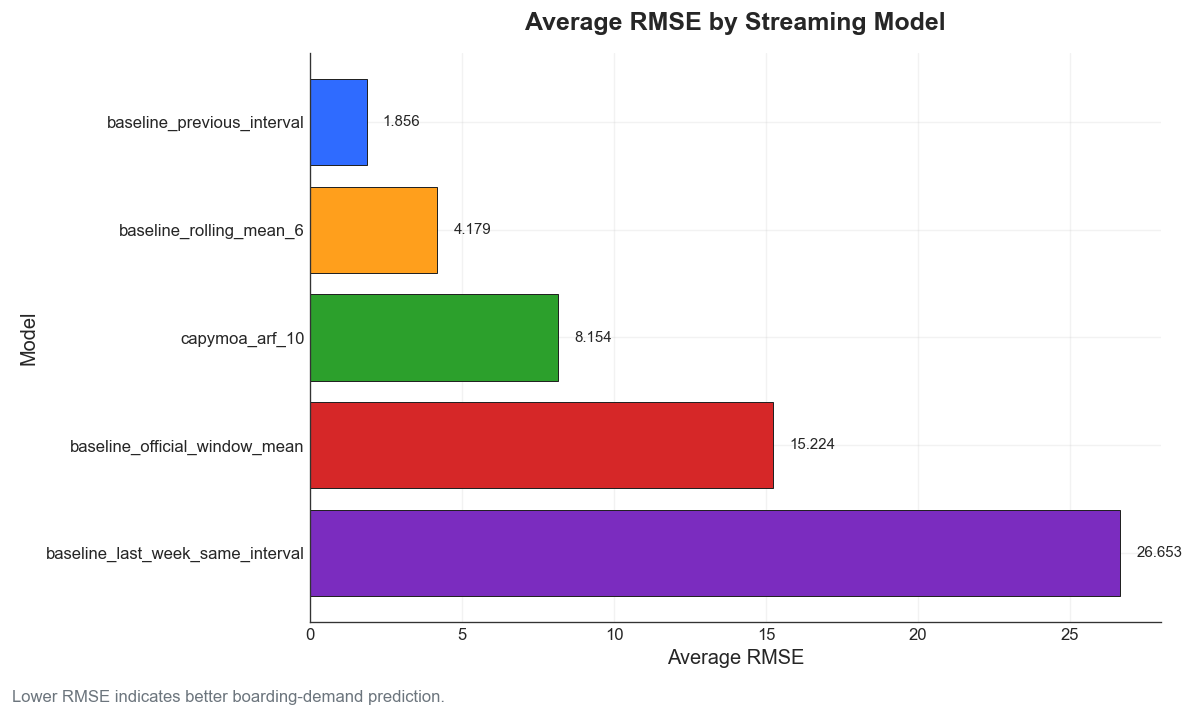

In [8]:
# ============================================================
# FIGURE 1: AVERAGE RMSE BY MODEL
# Lower RMSE means better predictive performance.
# ============================================================

plot_df = model_summary.sort_values("mean_rmse", ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, 5.8))

bars = ax.barh(
    plot_df["model"],
    plot_df["mean_rmse"],
    color=MODEL_COLORS[:len(plot_df)],
    edgecolor="#222222",
    linewidth=0.6
)

ax.set_title("Average RMSE by Streaming Model", pad=14)
ax.set_xlabel("Average RMSE")
ax.set_ylabel("Model")
ax.invert_yaxis()

add_value_labels_horizontal(ax, plot_df["mean_rmse"].values, fmt="{:.3f}")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

caption = "Lower RMSE indicates better boarding-demand prediction."
fig.text(0.01, -0.02, caption, fontsize=10, color=COLORS["gray"])

plt.tight_layout()
save_figure("E2_average_rmse_by_model_polished.png")
plt.show()

Saved figure: D:\MLDS\concept_drifter\figures\role_E_polished\E2_average_mae_by_model_polished.png


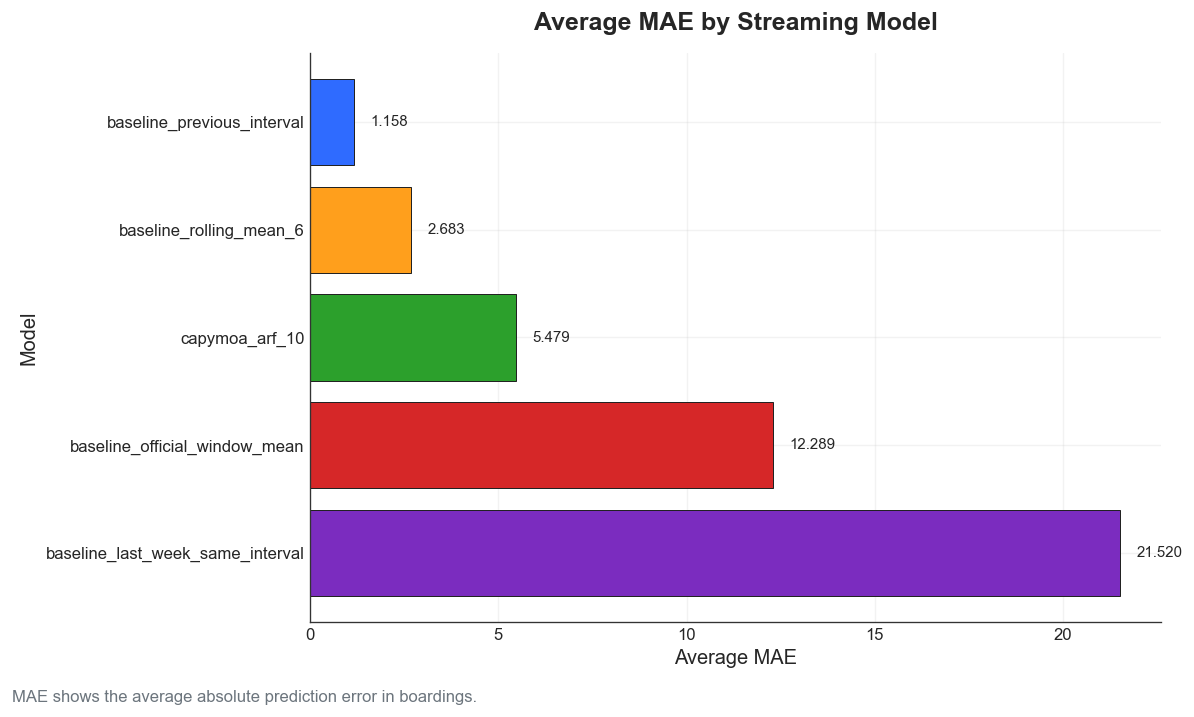

In [9]:
# ============================================================
# FIGURE 2: AVERAGE MAE BY MODEL
# MAE is easier to interpret as average absolute error.
# ============================================================

plot_df = model_summary.sort_values("mean_mae", ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, 5.8))

bars = ax.barh(
    plot_df["model"],
    plot_df["mean_mae"],
    color=MODEL_COLORS[:len(plot_df)],
    edgecolor="#222222",
    linewidth=0.6
)

ax.set_title("Average MAE by Streaming Model", pad=14)
ax.set_xlabel("Average MAE")
ax.set_ylabel("Model")
ax.invert_yaxis()

add_value_labels_horizontal(ax, plot_df["mean_mae"].values, fmt="{:.3f}")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

caption = "MAE shows the average absolute prediction error in boardings."
fig.text(0.01, -0.02, caption, fontsize=10, color=COLORS["gray"])

plt.tight_layout()
save_figure("E2_average_mae_by_model_polished.png")
plt.show()

Saved figure: D:\MLDS\concept_drifter\figures\role_E_polished\E2_windowed_rmse_over_time_polished.png


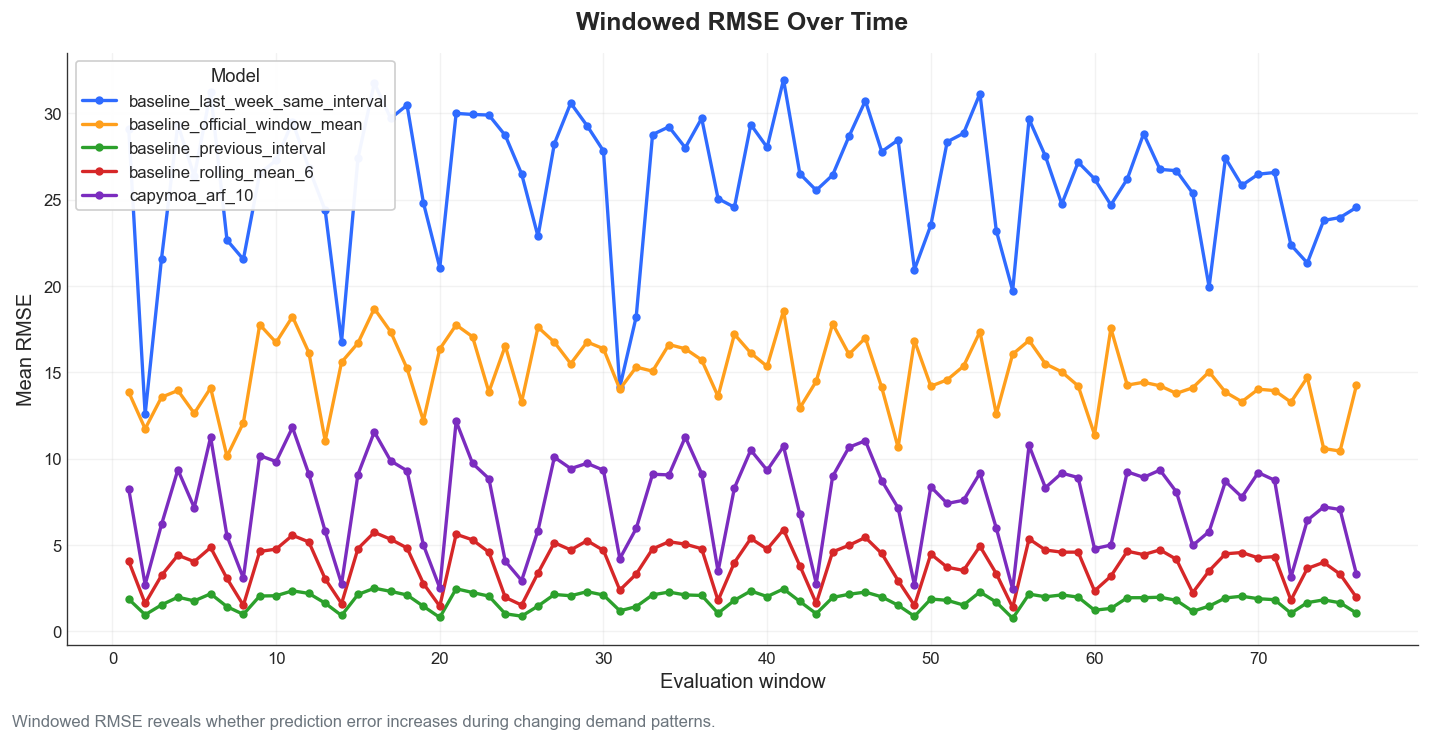

In [10]:
# ============================================================
# FIGURE 3: WINDOWED RMSE OVER TIME
# Important for data-stream evaluation.
# Shows how model error changes as the stream evolves.
# ============================================================

windowed_rmse = (
    windowed
    .groupby(["window_id", "model"], as_index=False)
    .agg(mean_rmse=("rmse", "mean"))
)

fig, ax = plt.subplots(figsize=(12, 6))

for idx, (model_name, group) in enumerate(windowed_rmse.groupby("model")):
    group = group.sort_values("window_id")
    
    ax.plot(
        group["window_id"],
        group["mean_rmse"],
        marker="o",
        markersize=4,
        linewidth=2,
        label=model_name,
        color=MODEL_COLORS[idx % len(MODEL_COLORS)]
    )

ax.set_title("Windowed RMSE Over Time", pad=14)
ax.set_xlabel("Evaluation window")
ax.set_ylabel("Mean RMSE")

ax.legend(title="Model", loc="best")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

caption = "Windowed RMSE reveals whether prediction error increases during changing demand patterns."
fig.text(0.01, -0.02, caption, fontsize=10, color=COLORS["gray"])

plt.tight_layout()
save_figure("E2_windowed_rmse_over_time_polished.png")
plt.show()

Saved figure: D:\MLDS\concept_drifter\figures\role_E_polished\E2_windowed_mae_over_time_polished.png


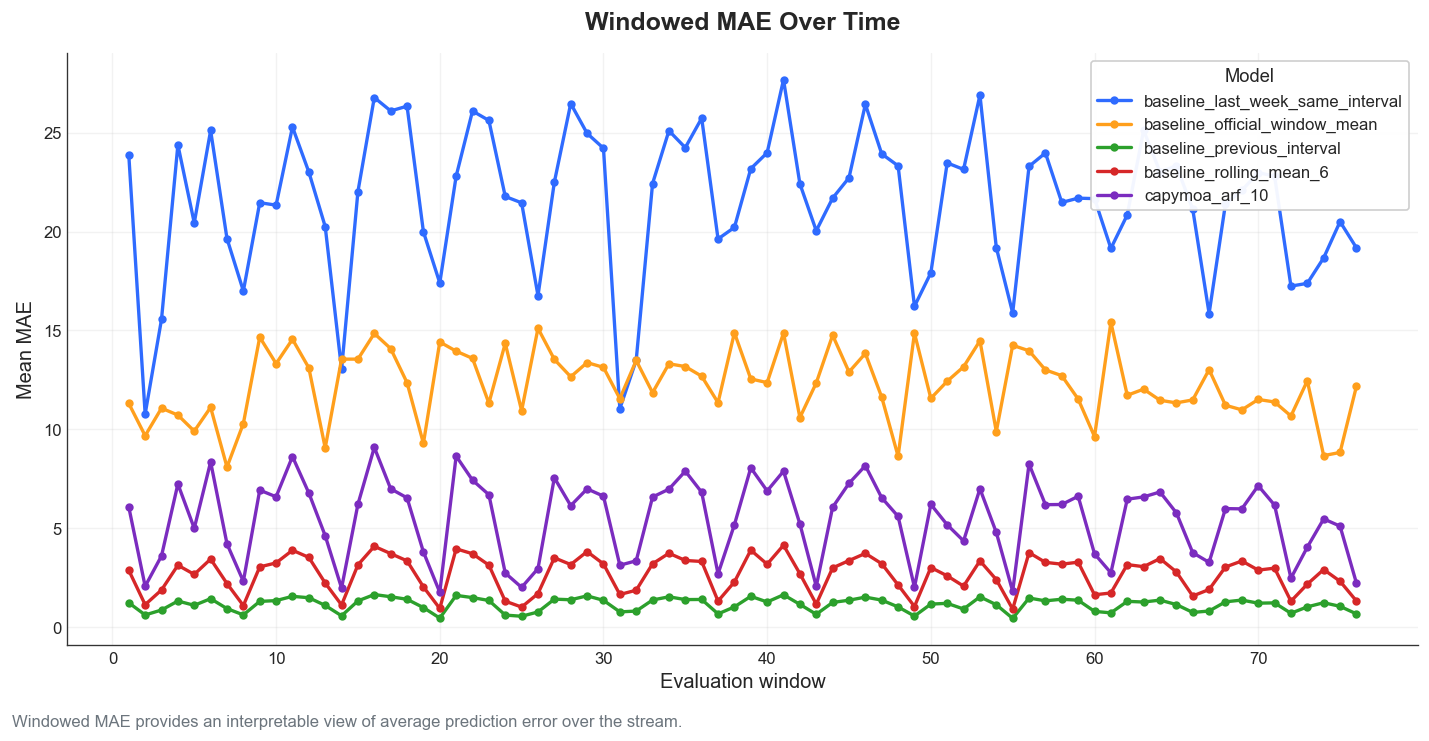

In [11]:
# ============================================================
# FIGURE 4: WINDOWED MAE OVER TIME
# Shows average absolute error across evaluation windows.
# ============================================================

windowed_mae = (
    windowed
    .groupby(["window_id", "model"], as_index=False)
    .agg(mean_mae=("mae", "mean"))
)

fig, ax = plt.subplots(figsize=(12, 6))

for idx, (model_name, group) in enumerate(windowed_mae.groupby("model")):
    group = group.sort_values("window_id")
    
    ax.plot(
        group["window_id"],
        group["mean_mae"],
        marker="o",
        markersize=4,
        linewidth=2,
        label=model_name,
        color=MODEL_COLORS[idx % len(MODEL_COLORS)]
    )

ax.set_title("Windowed MAE Over Time", pad=14)
ax.set_xlabel("Evaluation window")
ax.set_ylabel("Mean MAE")

ax.legend(title="Model", loc="best")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

caption = "Windowed MAE provides an interpretable view of average prediction error over the stream."
fig.text(0.01, -0.02, caption, fontsize=10, color=COLORS["gray"])

plt.tight_layout()
save_figure("E2_windowed_mae_over_time_polished.png")
plt.show()

In [12]:
# ============================================================
# PREPARE PEAK BOUNDARY DATA
# Converts dates and minutes-after-midnight into readable fields.
# ============================================================

boundaries_plot = boundaries.copy()

if "date" in boundaries_plot.columns:
    boundaries_plot["date"] = pd.to_datetime(boundaries_plot["date"])

if "start_min" in boundaries_plot.columns:
    boundaries_plot["start_time"] = boundaries_plot["start_min"].apply(minutes_to_hhmm)

if "end_min" in boundaries_plot.columns:
    boundaries_plot["end_time"] = boundaries_plot["end_min"].apply(minutes_to_hhmm)

display(boundaries_plot.head())

boundary_readable_path = POLISHED_TABLE_DIR / "E2_boundary_points_readable.csv"
boundaries_plot.to_csv(boundary_readable_path, index=False)

print("Saved table:", boundary_readable_path)

,stop,period,date,start_min,weekend,holiday,rain,start_time
0,44783654,AM,2024-03-25,645,0,0,0,10:45
1,44783654,AM,2024-04-04,560,0,0,1,09:20
2,44783654,AM,2024-04-09,645,0,0,0,10:45
3,44783654,AM,2024-04-10,645,0,0,1,10:45
4,44783654,AM,2024-04-22,640,0,0,1,10:40


Saved table: D:\MLDS\concept_drifter\outputs\role_E_polished\E2_boundary_points_readable.csv


Saved figure: D:\MLDS\concept_drifter\figures\role_E_polished\E2_peak_boundary_over_time_polished.png


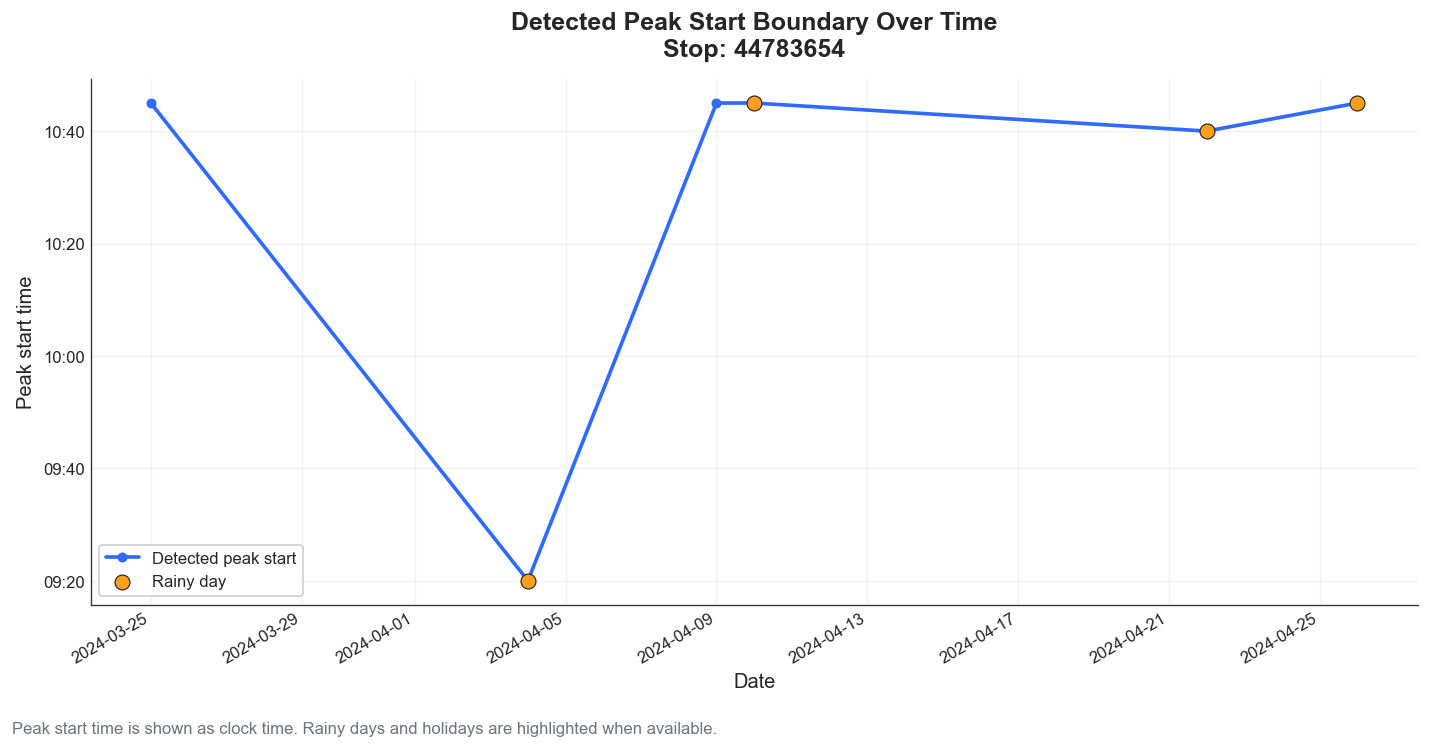

In [13]:
# ============================================================
# FIGURE 5: DETECTED PEAK START OVER TIME
# Shows how the real peak boundary changes day by day.
# ============================================================

# Choose one stop automatically
example_df = boundaries_plot.copy()

# Prefer AM/morning period if available
if "period" in example_df.columns:
    morning_candidate = example_df[
        example_df["period"].astype(str).str.lower().str.contains("am|morning")
    ]
    if len(morning_candidate) > 0:
        example_df = morning_candidate

# Choose first available stop
if "stop" in example_df.columns:
    selected_stop = example_df["stop"].dropna().unique()[0]
    example_df = example_df[example_df["stop"] == selected_stop]
else:
    selected_stop = "Selected stop"

example_df = example_df.sort_values("date")

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    example_df["date"],
    example_df["start_min"],
    marker="o",
    markersize=5,
    linewidth=2.2,
    color=COLORS["blue"],
    label="Detected peak start"
)

# Highlight rainy days if rain column exists
if "rain" in example_df.columns:
    rainy = example_df[example_df["rain"].astype(str).str.lower().isin(["true", "1", "yes"])]
    if len(rainy) > 0:
        ax.scatter(
            rainy["date"],
            rainy["start_min"],
            s=80,
            color=COLORS["orange"],
            edgecolor="#222222",
            linewidth=0.7,
            label="Rainy day",
            zorder=5
        )

# Highlight holidays if holiday column exists
if "holiday" in example_df.columns:
    holiday = example_df[example_df["holiday"].astype(str).str.lower().isin(["true", "1", "yes"])]
    if len(holiday) > 0:
        ax.scatter(
            holiday["date"],
            holiday["start_min"],
            s=100,
            color=COLORS["red"],
            edgecolor="#222222",
            linewidth=0.7,
            label="Holiday",
            zorder=6
        )

ax.set_title(f"Detected Peak Start Boundary Over Time\nStop: {selected_stop}", pad=14)
ax.set_xlabel("Date")
ax.set_ylabel("Peak start time")
ax.yaxis.set_major_formatter(FuncFormatter(hhmm_axis_formatter))

ax.legend(loc="best")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=30, ha="right")

caption = "Peak start time is shown as clock time. Rainy days and holidays are highlighted when available."
fig.text(0.01, -0.03, caption, fontsize=10, color=COLORS["gray"])

plt.tight_layout()
save_figure("E2_peak_boundary_over_time_polished.png")
plt.show()

In [14]:
# ============================================================
# PEAK SUMMARY TABLE
# Saves AM/PM summary in polished output folder.
# ============================================================

display(ampm.head())

peak_summary_path = POLISHED_TABLE_DIR / "E2_peak_boundary_summary.csv"
ampm.to_csv(peak_summary_path, index=False)

print("Saved table:", peak_summary_path)

,stop,label,period,n_days,official,weekday,weekend,holiday,weekend_shift_min,rain_shift_min,boundary_drift_days,detector
0,44783654,UFBA university,AM,6,06:00,10:30,--:--,--:--,NaN,-22.5,4.0,DEV-fallback
1,44783654,UFBA university,PM,29,17:00,17:01,19:15,--:--,133.4,-22.0,13.0,DEV-fallback
2,43768720,Lapa Station,AM,62,06:00,06:09,06:20,--:--,10.9,0.2,59.0,DEV-fallback
3,43768720,Lapa Station,PM,20,17:00,17:52,18:14,--:--,21.5,11.7,10.0,DEV-fallback
4,230565994,Itapua Beach,AM,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Saved table: D:\MLDS\concept_drifter\outputs\role_E_polished\E2_peak_boundary_summary.csv


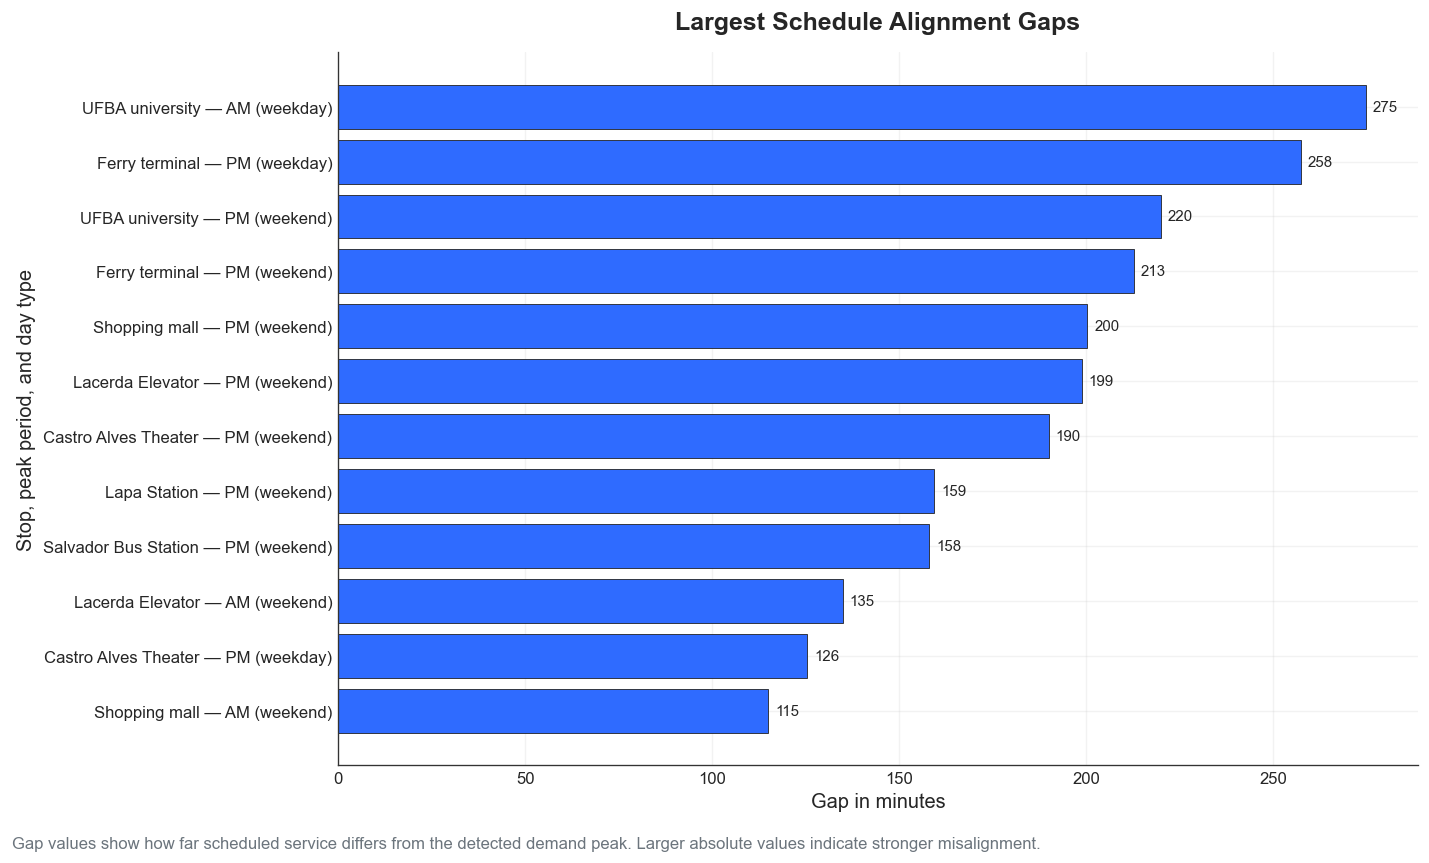

Saved figure: D:\MLDS\concept_drifter\figures\role_E_polished\E2_schedule_alignment_gap_polished_fixed.png


In [15]:
# ============================================================
# FIGURE 6: SCHEDULE ALIGNMENT GAP
# Shows where scheduled service is earlier/later than real demand.
# ============================================================

schedule_plot = schedule.copy()

# Create readable plotting label
if "label" in schedule_plot.columns and "period" in schedule_plot.columns:
    schedule_plot["plot_label"] = (
        schedule_plot["label"].astype(str) + " — " + schedule_plot["period"].astype(str)
    )
elif "stop" in schedule_plot.columns and "period" in schedule_plot.columns:
    schedule_plot["plot_label"] = (
        schedule_plot["stop"].astype(str) + " — " + schedule_plot["period"].astype(str)
    )
else:
    schedule_plot["plot_label"] = schedule_plot.index.astype(str)

# Add day_type if available, so duplicate labels do not overlap
if "day_type" in schedule_plot.columns:
    schedule_plot["plot_label"] = (
        schedule_plot["plot_label"] + " (" + schedule_plot["day_type"].astype(str) + ")"
    )

# Keep top 12 largest gaps for cleaner chart
schedule_plot["abs_gap"] = schedule_plot["gap_min"].abs()
schedule_top = schedule_plot.sort_values("abs_gap", ascending=False).head(12).copy()

# Sort for cleaner horizontal chart
schedule_top = schedule_top.sort_values("gap_min")

bar_colors = [
    COLORS["red"] if x < 0 else COLORS["blue"]
    for x in schedule_top["gap_min"]
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    schedule_top["plot_label"],
    schedule_top["gap_min"],
    color=bar_colors,
    edgecolor="#222222",
    linewidth=0.5
)

ax.axvline(0, color="#111111", linewidth=1)

ax.set_title("Largest Schedule Alignment Gaps", pad=14)
ax.set_xlabel("Gap in minutes")
ax.set_ylabel("Stop, peak period, and day type")

# Correct bar labels
ax.bar_label(
    bars,
    labels=[f"{v:.0f}" for v in schedule_top["gap_min"]],
    padding=4,
    fontsize=9
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

caption = (
    "Gap values show how far scheduled service differs from the detected demand peak. "
    "Larger absolute values indicate stronger misalignment."
)
fig.text(0.01, -0.02, caption, fontsize=10, color=COLORS["gray"])

plt.tight_layout()

fig_path = POLISHED_FIG_DIR / "E2_schedule_alignment_gap_polished_fixed.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=300)

plt.show()

print("Saved figure:", fig_path)

In [16]:
# ============================================================
# DRIFT SUMMARY TABLE
# Saves concept drift output from Role D for report use.
# ============================================================

display(drift.head())

drift_summary_path = POLISHED_TABLE_DIR / "E2_drift_summary.csv"
drift.to_csv(drift_summary_path, index=False)

print("Saved table:", drift_summary_path)

,stop,label,arf_rmse,perinstance_adwin_detections,perinstance_drift_days,daily_rmse_adwin_drift_days,backend
0,43768720,Lapa Station,67.104,186.0,86.0,0.0,capymoa_adwin
1,258781031,Salvador Bus Station,12.482,136.0,79.0,0.0,capymoa_adwin
2,44783914,Lacerda Elevator,4.263,119.0,77.0,0.0,capymoa_adwin
3,47568123,Shopping mall,1.629,126.0,80.0,0.0,capymoa_adwin
4,44072192,Castro Alves Theater,1.281,58.0,35.0,0.0,capymoa_adwin


Saved table: D:\MLDS\concept_drifter\outputs\role_E_polished\E2_drift_summary.csv


In [17]:
# ============================================================
# FINAL CHECK
# Lists all polished outputs created by this notebook.
# ============================================================

print("Polished figures:")
for f in sorted(POLISHED_FIG_DIR.glob("E2_*.png")):
    print("-", f.name)

print("\nPolished tables:")
for f in sorted(POLISHED_TABLE_DIR.glob("E2_*.csv")):
    print("-", f.name)

print("\nRole E docs:")
for f in sorted(ROLE_E_DIR.glob("E2_*.md")):
    print("-", f.name)

Polished figures:
- E2_average_mae_by_model_polished.png
- E2_average_rmse_by_model_polished.png
- E2_peak_boundary_over_time_polished.png
- E2_schedule_alignment_gap_polished_fixed.png
- E2_windowed_mae_over_time_polished.png
- E2_windowed_rmse_over_time_polished.png

Polished tables:
- E2_best_model_by_stop.csv
- E2_boundary_points_readable.csv
- E2_drift_summary.csv
- E2_model_comparison_summary.csv
- E2_peak_boundary_summary.csv

Role E docs:
